# 0. A primer on Bayesian statistics, for trufl
> Belief about a unit's contamination as a probability distribution, updated by samples, and used to decide where to sample next

Background for the temporary series on the `scoring-experiments` branch, best read before notebook 5:

0. A primer on Bayesian statistics, for trufl (this notebook)
1. A sampling campaign, round by round
2. The MCDM layer
3. What a good campaign means
4. The sawtooth in the restriction rule
5. From `bayes` to `voi`
6. Spatial correlation and where to place samples

Every idea here is shown on the question trufl's decision-aware strategies ask about each unit.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import beta, binom, betabinom

## The question

Take one unit, such as a municipality. Call `share` the part of its area above the permissible level. The DSS4NAFA rule restricts the unit when more than 10% of its samples are above the level, aiming at units whose `share` exceeds 10%. Nobody knows `share`. Each random sample lands above the level with probability `share`, so after `n` samples the number above the level, `k`, is binomial.

The obvious estimate is `k / n`. With few samples it says too much. After 6 samples with none above the level, `k / n` is 0, as if the unit were certainly clean. With 1 sample above the level out of 1, it is 100%. A campaign has 1 to 15 samples per unit, which is where this matters most.

In [ ]:
accepted = 0.1

## Belief as a distribution

Bayesian statistics describes what we know about `share` as a probability distribution over its possible values, from 0 to 1. Three pieces:

- The prior: what we believe before the samples.
- The likelihood: how probable the observed samples are for each value of `share`. With `k` of `n` above the level, it is `share^k * (1 - share)^(n - k)`.
- The posterior: prior times likelihood, rescaled to sum to 1. It is what we believe after the samples.

On a grid of possible shares, all three are plain arrays. Here, 1 of 12 samples above the level, starting from a prior that slightly favours shares near 0 and 1 (explained below):

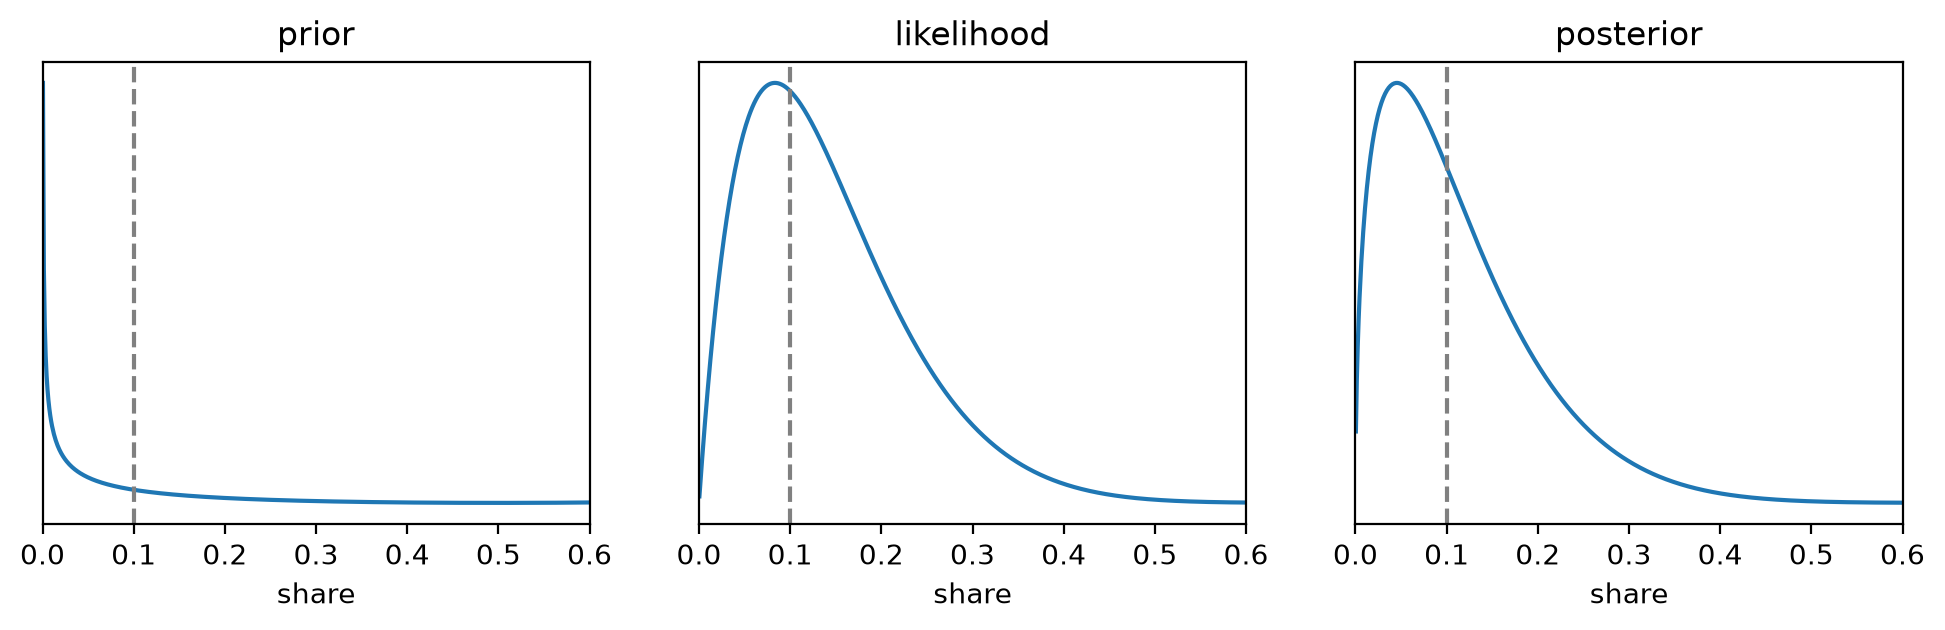

In [ ]:
grid = np.linspace(0.0005, 0.9995, 1000)
k, n = 1, 12
prior = beta.pdf(grid, 0.5, 0.5)
likelihood = grid**k * (1 - grid)**(n - k)
posterior = prior * likelihood
posterior /= posterior.sum()

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, y) in zip(axs, {'prior': prior / prior.sum(), 'likelihood': likelihood / likelihood.sum(), 'posterior': posterior}.items()):
    ax.plot(grid, y); ax.axvline(accepted, color='grey', ls='--')
    ax.set(title=name, xlabel='share', yticks=[], xlim=(0, 0.6))

## The beta shortcut

When the prior is a beta distribution, Beta(a, b), the posterior after `k` of `n` samples above the level is again a beta distribution: Beta(a + k, b + n - k). No grid is needed. The prior's `a` and `b` act like exceedances and non-exceedances already seen. This is the formula in `bayes`, `expected_wrong` and `voi`. It matches the grid:

In [ ]:
shortcut = beta.pdf(grid, 0.5 + k, 0.5 + n - k)
shortcut /= shortcut.sum()
assert np.abs(shortcut - posterior).max() < 1e-9

## Choosing a prior

Beta(0.5, 0.5), the Jeffreys prior, says almost nothing: it is worth one sample in total, and lets the samples speak. trufl uses it when there is no prior information.

An airborne survey gives a prior estimate `s0` of the share. trufl turns it into Beta(0.5 + m s0, 0.5 + m (1 - s0)), where `m` is how many samples the survey is worth. The larger `m`, the more samples it takes to overrule the survey. If the survey is wrong, that cost is real. Here the truth is 5%, the survey says 30%, and samples arrive one at a time:

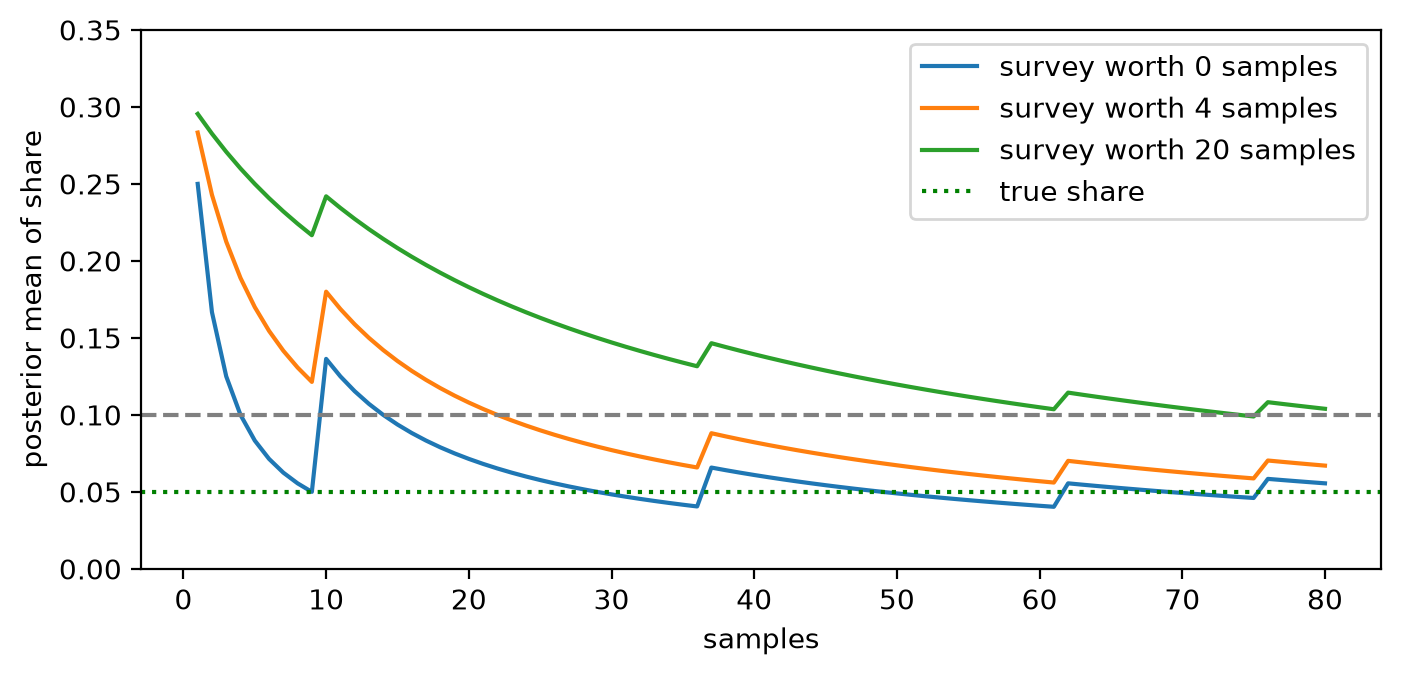

{0: 5, 4: 23, 20: 75}

In [ ]:
rng = np.random.default_rng(1)
k_so_far = np.cumsum(rng.random(80) < 0.05)
n_so_far = np.arange(1, 81)
fig, ax = plt.subplots(figsize=(8, 3.5))
first_below = {}
for m in (0, 4, 20):
    a0, b0 = 0.5 + m * 0.3, 0.5 + m * 0.7
    mean = (a0 + k_so_far) / (a0 + b0 + n_so_far)
    first_below[m] = int(n_so_far[np.argmax(mean < accepted)])
    ax.plot(n_so_far, mean, label=f'survey worth {m} samples')
ax.axhline(0.05, color='green', ls=':', label='true share')
ax.axhline(accepted, color='grey', ls='--')
ax.set(xlabel='samples', ylabel='posterior mean of share', ylim=(0, 0.35))
ax.legend()
first_below

With no survey, the posterior mean falls below 10% after 5 samples. With the survey worth 4 samples, after 23; worth 20 samples, after 75. A survey's weight should follow its quality: in the experiments, a poor survey worth 20 samples made decisions worse than ignoring it.

## Updating round by round

The posterior after one round is the prior for the next. Updating round by round, or all at once with every sample, gives the same posterior: only the totals `k` and `n` count. This is why trufl can recompute each unit's posterior from all samples so far at every round:

In [ ]:
a, b = 0.5, 0.5
for k_round, n_round in [(0, 3), (1, 4), (0, 5)]:
    a, b = a + k_round, b + n_round - k_round
assert (a, b) == (0.5 + 1, 0.5 + 12 - 1)
(a, b)

(1.5, 11.5)

## Questions the posterior answers

The posterior answers questions `k / n` cannot:

- The probability that the unit should be restricted: the posterior's area above 10%.
- A credible interval: a range that holds `share` with a given probability, here 90%.

In [ ]:
rows = {}
for k, n in [(0, 1), (0, 6), (1, 12), (3, 10), (2, 40)]:
    post = beta(0.5 + k, 0.5 + n - k)
    rows[f'{k} of {n}'] = {'k / n': k / n, 'P(share > 10%)': post.sf(accepted), '5%': post.ppf(0.05), '95%': post.ppf(0.95)}
pd.DataFrame(rows).T.round(3)

,k / n,P(share > 10%),5%,95%
0 of 1,0.000,0.604,0.002,0.771
0 of 6,0.000,0.251,0.000,0.264
1 of 12,0.083,0.480,0.015,0.283
3 of 10,0.300,0.969,0.117,0.558
2 of 40,0.050,0.142,0.014,0.132


After 6 samples with none above the level, `k / n` is 0, but there is still a 25% chance the unit should be restricted, and the 90% interval reaches above 20%. With 40 samples the interval is much narrower.

## Predicting the next samples

To plan sampling, trufl needs to predict what the next samples will show. For a known `share`, the number of exceedances in the next `m` samples is binomial. Since `share` is uncertain, the prediction averages the binomial over the posterior. That average is the beta-binomial distribution. For a unit with 1 of 9 samples above the level, the next 10 samples:

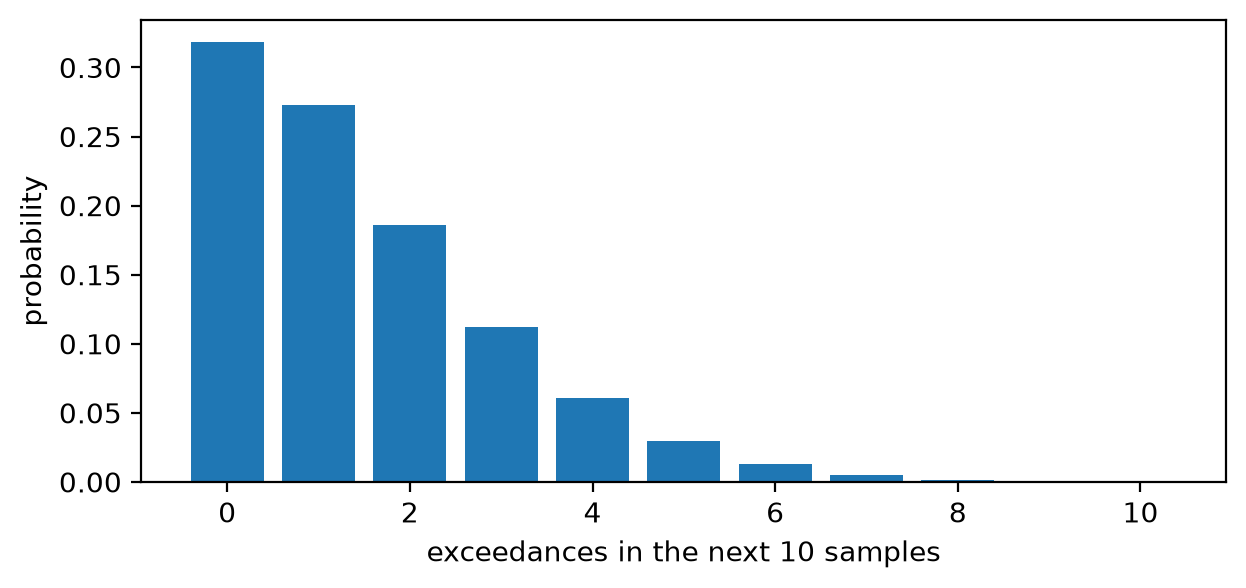

In [ ]:
k, n, m = 1, 9, 10
pred = betabinom.pmf(np.arange(m + 1), m, 0.5 + k, 0.5 + n - k)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(m + 1), pred)
ax.set(xlabel=f'exceedances in the next {m} samples', ylabel='probability');

`expected_wrong` in `07_scoring.ipynb` does this averaging, with one more step: for each `share`, it checks whether the decision those samples lead to matches what that `share` calls for, then averages the result over the posterior. The result is the probability that the dashboard's decision will be wrong after `m` more samples.

## Deciding under uncertainty

A decision rule can use the posterior directly. Suppose a missed restriction costs `r` times as much as a needless one. Restricting has expected cost P(share ≤ 10%), and not restricting costs `r` × P(share > 10%). Restricting is the cheaper choice when P(share > 10%) is above 1 / (1 + r). The more a missed restriction costs, the lower the bar for restricting:

In [ ]:
{f'missed costs {r}x needless': round(1 / (1 + r), 3) for r in (1, 3, 10)}

{'missed costs 1x needless': 0.5,
 'missed costs 3x needless': 0.25,
 'missed costs 10x needless': 0.091}

The DSS4NAFA rule does not work this way: it decides from the share of samples alone, ignores any survey and makes no cost explicit. Whether a rule like this one should replace it is an open question for DSS4NAFA, listed in `scoring-design.md`.

## Value of information

A sample is worth what it is expected to save: how much it lowers the expected cost of the decision it informs. That is the value of information. It is high where the decision is uncertain and samples can still change it, and close to zero where the decision is already settled, or cannot change with a few more samples.

`voi` puts this into practice: it gives each sample to the unit where it lowers the probability of a wrong decision the most. Notebook 5 shows it on toy units, including the cases where one more sample makes things worse.

## What trufl assumes

- Samples within a unit are placed at random. Random placement makes them independent even when the contamination is spatially correlated, so the binomial model holds. Samples taken where it was convenient, such as clusters near roads, are not independent, and make the posterior more confident than it should be. Spread placement does the opposite. Notebook 6 shows both.
- A unit is reduced to one number, `share`. The model ignores how far above or below the level each value is. Notebook 4 shows a rule that uses the values themselves.
- The prior's weight `m` must be chosen. Nothing in the data sets it yet.
- Measurements are exact. Measurement error, the other half of #11, is not modelled yet.